# Fitting the Ideal Observer to a Participant

This notebook fits the context-model and reward-model hyperparameters of the ideal observer to a participant's choices, and checks the fit on a **simulated participant** whose true hyperparameters are known (parameter recovery).

1. Define the experiment, and the ideal observer with its free hyperparameters and their priors
2. Draw a random participant from the prior, and simulate their session
3. Check the noise of the likelihood estimate
4. Sample the posterior over the hyperparameters by pseudo-marginal Metropolis-Hastings (see `fitting.py`)
5. Compare the posterior with the true values

To fit a real participant instead, replace the simulated `data` in step 2 with `Dataset(observations=..., actions=..., rewards=...)` from their session.

In [1]:
import time
import warnings

import numpy as np
from scipy.special import logit
from scipy.stats import norm
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter, NullLocator

from models_context import CjCRP
from models_obs_rew import ConjugateGaussianInvGam, ConjugateBernoulli
from experiment import ExperimentalEnv, CPP_BACKEND_ERROR
from fitting import FreeParam, FitModel, TRANSFORMS, simulate, log_likelihood_sd, run_chains, rhat, ess

np.set_printoptions(precision=4, suppress=True, linewidth=250)

# Categorical colours, assigned in this order; ink colours for reference marks
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK = "#0b0b0b"
INK_MUTED = "#52514e"


def set_scale(ax, which: str, transform: str):
    '''
    Set a log or logit scale on the x or y axis of ax, with plain tick labels (0.01, 0.1, 1, ...)
    '''
    axis = ax.xaxis if which == "x" else ax.yaxis
    (ax.set_xscale if which == "x" else ax.set_yscale)(transform)
    if transform == "logit":
        axis.set_major_locator(FixedLocator([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.5, 0.7, 0.9, 0.97, 0.99]))
        axis.set_minor_locator(NullLocator())
    axis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    axis.set_minor_formatter(NullFormatter())

In [2]:
# Implementation of the ideal observer: "cpp" (IdealObsPFCpp) or "python" (IdealObsPF)
BACKEND = "cpp"

# The C++ backend has to be built for each machine (python cpp/build_cpp.py). Fitting with the Python backend is ~70x slower.
if BACKEND == "cpp" and CPP_BACKEND_ERROR is not None:
    warnings.warn(CPP_BACKEND_ERROR + " Falling back to the Python backend, which is only practical for small tests.")
    BACKEND = "python"

## Part 1: The Experiment and the Model

### The experiment
The same task as in `demo.ipynb`: two observation contexts and two reward contexts, each with two latent states, in four blocks of trials.
The last block combines the observations of context 0 with the rewards of context 1.

In [3]:
NOISE = 0.02
cov_all = np.eye(2) * NOISE

context_o_params = {
    0: {  # context 0
        0: {'loc': np.array([1.0, 0.0]),  'cov': cov_all},  # state 0
        1: {'loc': np.array([-1.0, 0.0]), 'cov': cov_all},  # state 1
    },
    1: {  # context 1
        0: {'loc': np.array([0.0, 1.0]),  'cov': cov_all},  # state 0
        1: {'loc': np.array([0.0, -1.0]), 'cov': cov_all},  # state 1
    },
}

context_r_params = {
    0: {  # context 0
        0: {'p_rew': np.array([1.0, 0.0, 0.0, 0.0])},  # state 0
        1: {'p_rew': np.array([0.0, 1.0, 0.0, 0.0])},  # state 1
    },
    1: {  # context 1
        0: {'p_rew': np.array([0.0, 0.0, 1.0, 0.0])},  # state 0
        1: {'p_rew': np.array([0.0, 0.0, 0.0, 1.0])},  # state 1
    },
}

env = ExperimentalEnv(context_o_params=context_o_params, context_r_params=context_r_params)

# Blocks of trials, run in order: (n_trials, c_o, c_r)
SCHEDULE = [
    (50, 0, 0),
    (50, 1, 1),
    (50, 0, 0),
    (50, 0, 1),
]

### The model and its free hyperparameters
The ideal observer uses a coupled jump CRP context model, a Normal-Inverse-Gamma observation model, and a Beta-Bernoulli reward model.

The **observation hyperparameters are frozen** at the values below. The free hyperparameters each have a Normal prior on an unconstrained scale (log for positive hyperparameters, logit for those in (0, 1)):

| Hyperparameter | Meaning | Prior median | Prior scale |
|---|---|---|---|
| `hyp_context.gamma` | probability of a context jump on each trial | 0.1 | logit-Normal, SD 1 |
| `hyp_context.alpha` | CRP concentration: how readily new contexts are created | 1.0 | log-Normal, SD 1 |
| `hyp_rew.alpha0` | prior pseudo-count of rewards, tied across the four actions | 0.1 | log-Normal, SD 1 |
| `hyp_rew.beta0` | prior pseudo-count of non-rewards, tied across the four actions | 0.5 | log-Normal, SD 1 |
| `lapse` | probability of a uniformly random action instead of the ideal observer's choice | 0.02 | logit-Normal, SD 1 |

The values of the free hyperparameters in `BASE_PARAMS` are placeholders, which are overridden during fitting.

In [4]:
BASE_PARAMS = {
    "type_context": CjCRP,
    "hyp_context":  {'gamma': 0.1, 'alpha': 0.5},
    "type_obs":     ConjugateGaussianInvGam,
    "hyp_obs":      {'mu0': np.array([0.0, 0.0]), 'kappa0': 0.1, 'alpha0': 2.0, 'beta0': 1.0},
    "type_rew":     ConjugateBernoulli,
    "hyp_rew":      {'alpha0': np.full(4, 0.05), 'beta0': np.full(4, 0.5)},
}

FREE_PARAMS = [
    FreeParam("hyp_context.gamma", "logit", prior_loc=logit(0.1),  prior_scale=1.0),
    FreeParam("hyp_context.alpha", "log",   prior_loc=np.log(1.0), prior_scale=1.0),
    FreeParam("hyp_rew.alpha0",    "log",   prior_loc=np.log(0.1), prior_scale=1.0),
    FreeParam("hyp_rew.beta0",     "log",   prior_loc=np.log(0.5), prior_scale=1.0),
    FreeParam("lapse",             "logit", prior_loc=logit(0.02), prior_scale=1.0),
]

model = FitModel(BASE_PARAMS, FREE_PARAMS)

# Labels for printing and plotting
LABELS = {
    "hyp_context.gamma": "γ  (jump probability)",
    "hyp_context.alpha": "α  (CRP concentration)",
    "hyp_rew.alpha0":    "α₀ (reward pseudo-count)",
    "hyp_rew.beta0":     "β₀ (non-reward pseudo-count)",
    "lapse":             "ε  (lapse rate)",
}
SYMBOLS = {"hyp_context.gamma": "γ", "hyp_context.alpha": "α", "hyp_rew.alpha0": "α₀", "hyp_rew.beta0": "β₀", "lapse": "ε"}

## Part 2: A Random Participant

The participant's true hyperparameters are drawn from the prior, and their session is simulated from the same model that is fitted, including lapses.

In [5]:
PARTICIPANT_SEED = 1   # None draws a new participant on every run
N_PARTICIPANT = 250    # number of particles of the simulated participant's ideal observer

theta_true = model.sample_prior(1, seed=PARTICIPANT_SEED)[0]
data = simulate(model, theta_true, env, SCHEDULE, N=N_PARTICIPANT, seed=PARTICIPANT_SEED, backend=BACKEND)

true_values = dict(zip(model.names, model.to_natural(theta_true)))
print("True hyperparameters of the participant:")
for name, value in true_values.items():
    print(f"  {LABELS[name]:<30} {value:.3f}")
print(f"\nMean reward over {len(data)} trials: {data.rewards.mean():.2f}")

True hyperparameters of the participant:
  γ  (jump probability)          0.136
  α  (CRP concentration)         2.274
  α₀ (reward pseudo-count)       0.139
  β₀ (non-reward pseudo-count)   0.136
  ε  (lapse rate)                0.048

Mean reward over 200 trials: 0.79


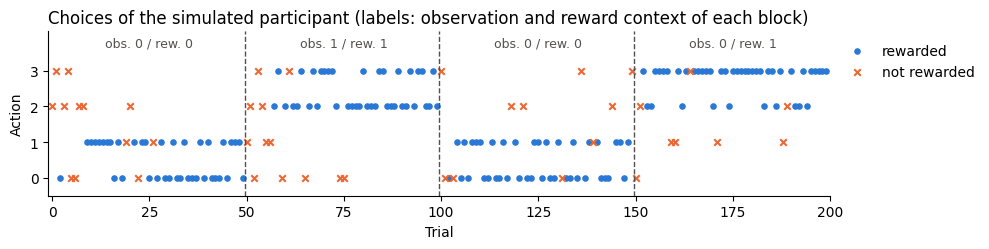

In [6]:
# The participant's choices, with the block boundaries
block_starts = np.cumsum([0] + [n_trials for n_trials, _, _ in SCHEDULE])
trials = np.arange(len(data))
rewarded = data.rewards == 1.0

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.scatter(trials[rewarded], data.actions[rewarded], s=14, color=COLOURS[0], label="rewarded")
ax.scatter(trials[~rewarded], data.actions[~rewarded], s=22, marker="x", color=COLOURS[1], label="not rewarded")
for start in block_starts[1:-1]:
    ax.axvline(start - 0.5, color=INK_MUTED, lw=1, ls="--")
for (n_trials, c_o, c_r), start in zip(SCHEDULE, block_starts):
    ax.text(start + n_trials / 2, 3.6, f"obs. {c_o} / rew. {c_r}", ha="center", va="bottom", fontsize=9, color=INK_MUTED)
ax.set_yticks(range(model.n_actions))
ax.set_ylim(-0.5, 4.1)
ax.set_xlim(-1, len(data))
ax.set_xlabel("Trial")
ax.set_ylabel("Action")
ax.set_title("Choices of the simulated participant (labels: observation and reward context of each block)", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Part 3: The Likelihood Estimate

The likelihood of the participant's choices is estimated by running the ideal observer on their observations, actions and rewards (see `fitting.py`).
The estimate is noisy, and Metropolis-Hastings mixes well if the standard deviation of the log-likelihood estimate is below ~1.5.
It is controlled by the number of particles `N` and of Thompson samples per particle `N_THOMPSON`, both of which also set the run time.

For a real participant the true hyperparameters are unknown, so check the noise at a rough estimate instead (e.g. the posterior median of a short first run).

In [7]:
N = 250          # number of particles of the ideal observer in the likelihood
N_THOMPSON = 3   # number of Thompson samples per particle, from which its action probabilities are estimated

N_REPEATS = 30
t = time.time()
ll_sd = log_likelihood_sd(model, theta_true, data, N, N_THOMPSON, n_repeats=N_REPEATS, backend=BACKEND)
seconds_per_eval = (time.time() - t) / N_REPEATS

print(f"SD of the log-likelihood estimate at the true hyperparameters: {ll_sd:.2f}")
print(f"Time per likelihood evaluation: {seconds_per_eval:.3f} s")
if ll_sd > 1.5:
    print("The estimate is noisy enough to slow down mixing: consider increasing N or N_THOMPSON.")

SD of the log-likelihood estimate at the true hyperparameters: 0.92
Time per likelihood evaluation: 0.136 s


## Part 4: Sampling the Posterior

Several chains are run in parallel from dispersed starting points drawn from the prior. During burn-in the random-walk proposal is adapted to the posterior, and the burn-in samples are discarded.

The number of effective samples grows in proportion to the number of chains, at almost no cost in run time as long as each chain has its own physical core.
Hyperthreads add little, so `N_WORKERS` should be at most the number of physical cores; chains beyond `N_WORKERS` wait for a free worker.

In [8]:
N_CHAINS = 16     # number of independent chains
N_WORKERS = 16    # number of worker processes running chains in parallel, at most the number of physical cores
N_BURNIN = 1000   # iterations during which the proposal is adapted, discarded
N_ITER = 3000     # iterations kept as posterior samples

theta0s = model.sample_prior(N_CHAINS, seed=0)  # dispersed starting points

# Rough estimate, as chains running in parallel are somewhat slower than a single evaluation above
n_rounds = int(np.ceil(N_CHAINS / N_WORKERS))
print(f"Expected run time: ~{n_rounds * (N_BURNIN + N_ITER) * seconds_per_eval / 60:.0f} min")

t = time.time()
chains = run_chains(model, data, theta0s, n_iter=N_ITER, n_burnin=N_BURNIN, N=N, n_workers=N_WORKERS, n_thompson=N_THOMPSON, backend=BACKEND, seed=0)
print(f"Done in {(time.time() - t) / 60:.1f} min")

Expected run time: ~9 min
Done in 10.8 min


### Convergence diagnostics
- **Traces** should look like stationary, overlapping noise.
- **Split R-hat** should be below ~1.01 (at most ~1.05 for a quick look). Higher values mean that the chains have not converged to the same distribution: increase `N_BURNIN`.
- **Effective sample size (ESS)** is the number of independent samples that the autocorrelated samples are worth. A few hundred are enough for medians and 95% intervals, ~1000 or more give smooth histograms. Increase `N_CHAINS` or `N_ITER` for more.
- **Acceptance rates** of 0.1-0.3 are expected with the noisy likelihood.

Acceptance rates: [0.21, 0.2, 0.16, 0.17, 0.15, 0.23, 0.19, 0.15, 0.23, 0.2, 0.21, 0.21, 0.16, 0.15, 0.21, 0.14]

                                  R-hat     ESS
  γ  (jump probability)           1.017    1009
  α  (CRP concentration)          1.014    1049
  α₀ (reward pseudo-count)        1.011    1209
  β₀ (non-reward pseudo-count)    1.010    1300
  ε  (lapse rate)                 1.023     659

(ESS out of 48000 samples)


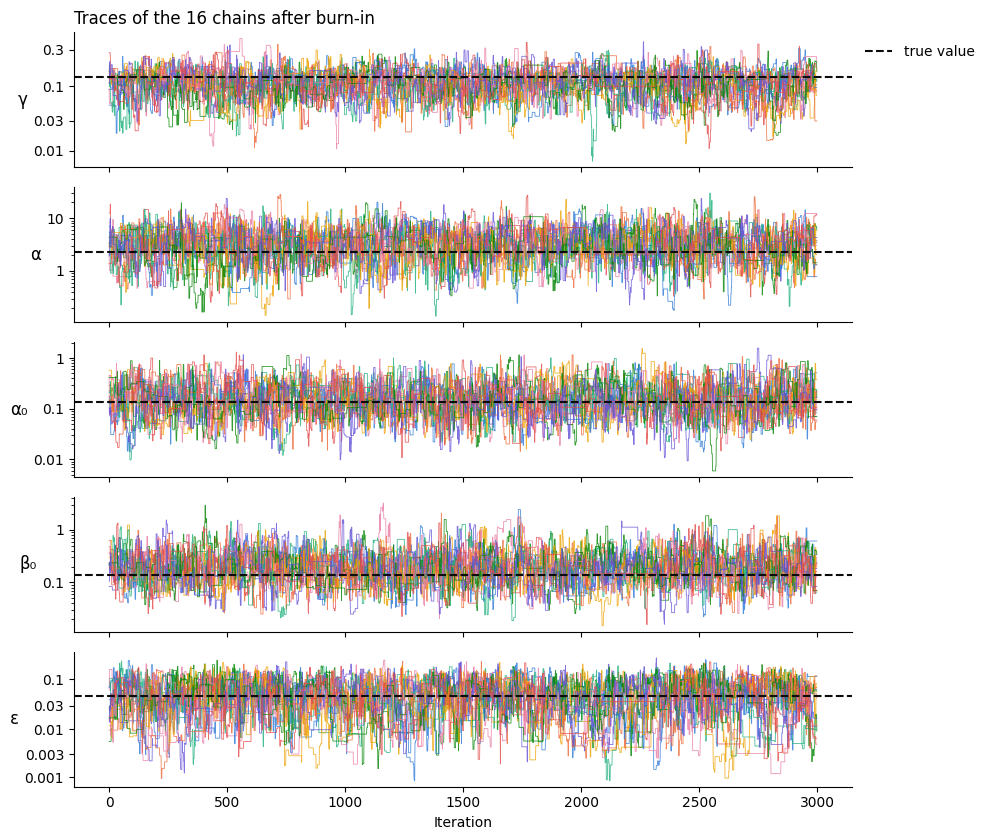

In [9]:
r_hats = rhat(chains)
ess_values = ess(chains)
print("Acceptance rates:", [round(chain.accept_rate, 2) for chain in chains])
print(f"\n{'':<32} {'R-hat':>6} {'ESS':>7}")
for name in model.names:
    print(f"  {LABELS[name]:<30} {r_hats[name]:>6.3f} {ess_values[name]:>7.0f}")
print(f"\n(ESS out of {sum(len(chain.theta) for chain in chains)} samples)")

fig, axes = plt.subplots(model.d, 1, figsize=(10, 1.7 * model.d), sharex=True)
for j, (ax, param) in enumerate(zip(axes, model.free_params)):
    # Chains reuse the colours if there are more of them than colours
    for c, chain in enumerate(chains):
        ax.plot(chain.natural[:, j], lw=0.6, alpha=0.8, color=COLOURS[c % len(COLOURS)])
    ax.axhline(true_values[param.name], color=INK, lw=1.5, ls="--", label="true value")
    set_scale(ax, "y", param.transform)
    ax.set_ylabel(SYMBOLS[param.name], rotation=0, ha="right", va="center", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
axes[0].set_title(f"Traces of the {len(chains)} chains after burn-in", loc="left")
axes[-1].set_xlabel("Iteration")
plt.tight_layout()
plt.show()

## Part 5: Posterior vs True Values

Each panel shows the posterior (pooled over chains), the prior, and the participant's true value, on the scale on which the hyperparameter is sampled (log or logit), with densities per unit of that scale.
A posterior that is much narrower than the prior means that the participant's choices are informative about that hyperparameter; a posterior that looks like the prior means that they are not.

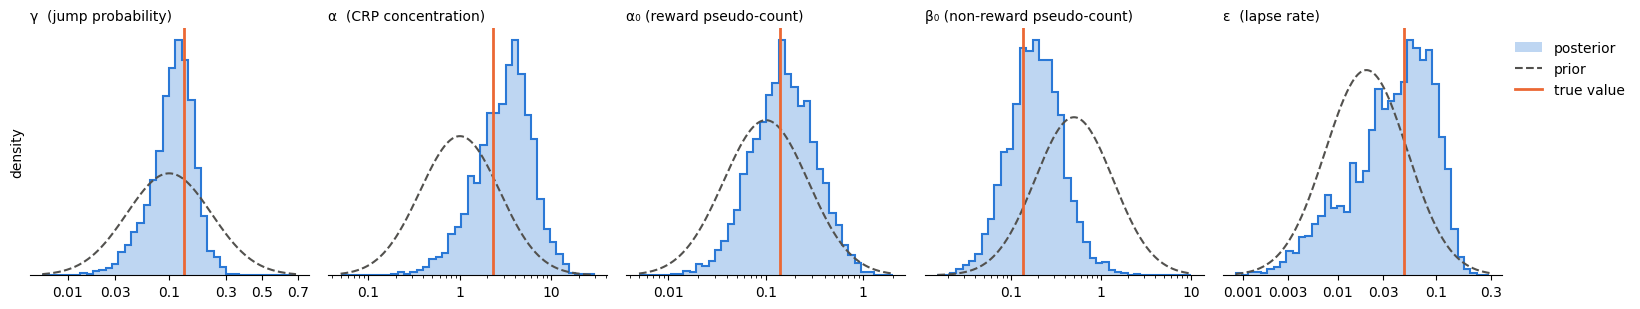

In [10]:
pooled_theta = np.concatenate([chain.theta for chain in chains])  # unconstrained scale [n_samples, d]

fig, axes = plt.subplots(1, model.d, figsize=(3.3 * model.d, 3.2))
for j, (ax, param) in enumerate(zip(axes, model.free_params)):
    inverse = TRANSFORMS[param.transform][1]
    samples = pooled_theta[:, j]
    true_u = theta_true[j]

    # Histogram and prior density on the unconstrained scale, drawn against the natural scale on a log / logit axis
    lo = min(param.prior_loc - 3 * param.prior_scale, samples.min(), true_u - 0.5)
    hi = max(param.prior_loc + 3 * param.prior_scale, samples.max(), true_u + 0.5)
    edges = np.linspace(lo, hi, 41)
    density, _ = np.histogram(samples, bins=edges, density=True)
    ax.stairs(density, inverse(edges), fill=True, color=COLOURS[0], alpha=0.3, label="posterior")
    ax.stairs(density, inverse(edges), color=COLOURS[0], lw=1.5)

    grid = np.linspace(lo, hi, 400)
    ax.plot(inverse(grid), norm.pdf(grid, param.prior_loc, param.prior_scale), color=INK_MUTED, lw=1.5, ls="--", label="prior")
    ax.axvline(true_values[param.name], color=COLOURS[1], lw=2, label="true value")

    set_scale(ax, "x", param.transform)
    ax.set_title(LABELS[param.name], fontsize=10, loc="left")
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].set_ylabel("density")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
plt.tight_layout()
plt.show()

In [11]:
# Posterior summaries. Shrinkage is the posterior SD over the prior SD on the unconstrained scale (1 = the data say nothing)
pooled = np.concatenate([chain.natural for chain in chains])
print(f"{'':<32} {'true':>7} {'median':>7}   {'95% interval':<17} {'covered':>7} {'shrinkage':>9}")
for j, name in enumerate(model.names):
    lo, med, hi = np.percentile(pooled[:, j], [2.5, 50, 97.5])
    true = true_values[name]
    covered = "yes" if lo <= true <= hi else "no"
    shrinkage = pooled_theta[:, j].std() / model.prior_scale[j]
    print(f"  {LABELS[name]:<30} {true:>7.3f} {med:>7.3f}   [{lo:.3f}, {hi:.3f}]{'':<3} {covered:>7} {shrinkage:>9.2f}")

                                    true  median   95% interval      covered shrinkage
  γ  (jump probability)            0.136   0.114   [0.035, 0.225]        yes      0.52
  α  (CRP concentration)           2.274   3.280   [0.628, 10.348]        yes      0.71
  α₀ (reward pseudo-count)         0.139   0.152   [0.033, 0.618]        yes      0.74
  β₀ (non-reward pseudo-count)     0.136   0.187   [0.048, 0.720]        yes      0.69
  ε  (lapse rate)                  0.048   0.043   [0.004, 0.138]        yes      1.00


### Trade-offs between hyperparameters
Pairs of posterior samples show which hyperparameters trade off against each other (elongated, tilted clouds), e.g. the two reward pseudo-counts, whose ratio sets the expected reward of a new context.

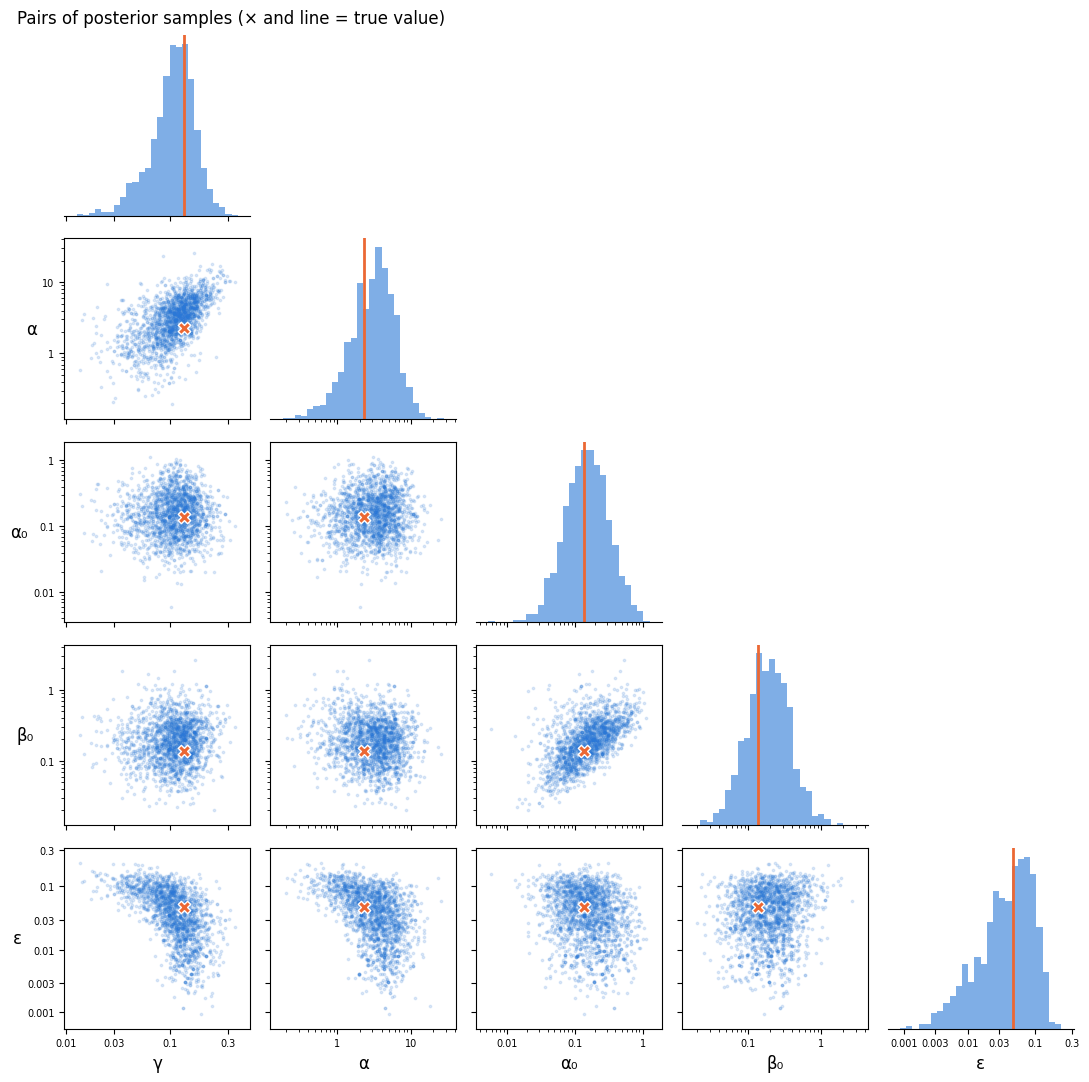

In [12]:
thinned = pooled[:: max(1, len(pooled) // 2000)]  # ~2000 samples, so that the scatter stays readable
thinned_theta = pooled_theta[:: max(1, len(pooled) // 2000)]

# Common limits for each hyperparameter, covering its samples and true value (on the unconstrained scale, with a margin)
limits = []
for j, param in enumerate(model.free_params):
    inverse = TRANSFORMS[param.transform][1]
    lo, hi = min(thinned_theta[:, j].min(), theta_true[j]), max(thinned_theta[:, j].max(), theta_true[j])
    limits.append((lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo), inverse))

fig, axes = plt.subplots(model.d, model.d, figsize=(2.2 * model.d, 2.2 * model.d))
for i, param_i in enumerate(model.free_params):
    for j, param_j in enumerate(model.free_params):
        ax = axes[i, j]
        if j > i:
            ax.axis("off")
            continue
        lo_j, hi_j, inverse_j = limits[j]
        if i == j:
            # Bins evenly spaced on the unconstrained scale, so that they are evenly spaced on the log / logit axis
            ax.hist(thinned[:, j], bins=inverse_j(np.linspace(lo_j, hi_j, 31)), color=COLOURS[0], alpha=0.6)
            ax.axvline(true_values[param_j.name], color=COLOURS[1], lw=2)
            ax.set_yticks([])
            ax.spines[["top", "right", "left"]].set_visible(False)
        else:
            lo_i, hi_i, inverse_i = limits[i]
            ax.scatter(thinned[:, j], thinned[:, i], s=3, color=COLOURS[0], alpha=0.15, rasterized=True)
            ax.scatter(true_values[param_j.name], true_values[param_i.name], s=80, marker="X", color=COLOURS[1], edgecolor="white", linewidth=1, zorder=3)
            set_scale(ax, "y", param_i.transform)
            ax.set_ylim(inverse_i(lo_i), inverse_i(hi_i))
        set_scale(ax, "x", param_j.transform)
        ax.set_xlim(inverse_j(lo_j), inverse_j(hi_j))
        ax.tick_params(which="both", labelleft=(j == 0 and i > 0), labelbottom=(i == model.d - 1))
        if i == model.d - 1:
            ax.set_xlabel(SYMBOLS[param_j.name], fontsize=12)
        if j == 0 and i > 0:
            ax.set_ylabel(SYMBOLS[param_i.name], fontsize=12, rotation=0, ha="right", va="center")
        ax.tick_params(labelsize=7)
fig.suptitle("Pairs of posterior samples (× and line = true value)", x=0.02, ha="left")
plt.tight_layout()
plt.show()